# 03 · Breakdowns: departments, sex of the household head, inequality

Going past the national table:
1. **Departments** — with the departmental expansion factor `fex_dpto`, as DANE does
2. **Sex of the household head** — requires merging the person file onto the household file
3. **Inequality** — weighted Gini by department, with the hand-written `gini()`
4. **Sampling uncertainty** — approximate 95% confidence intervals

Each breakdown is checked against a DANE publication before it is interpreted.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from povcol.load import load, household_head_sex, HH_KEYS
from povcol.weighted import weighted_rate, gini, ratio_se
from povcol import official

YEAR = 2025
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)
FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True)

hog = load(YEAR, "hogares")
hog["w_person"] = hog["fex"] * hog["nper"]          # national / urban-rural weight
hog["w_dpto"] = hog["fex_dpto"] * hog["nper"]       # departmental weight

## 1. Poverty by department

The 2025 file covers 23 departments plus Bogotá. DANE publishes departmental figures with a
separate expansion factor (`fex_dpto`), calibrated to departmental population projections.

In [2]:
def dept_stats(d):
    return pd.Series({
        "poverty": weighted_rate(d["pobre"], d["w_dpto"]),
        "extreme": weighted_rate(d["indigente"], d["w_dpto"]),
        "gini": gini(d["ingpcug"], d["w_dpto"]),
        "poverty_with_fex_c": weighted_rate(d["pobre"], d["w_person"]),
        "households_sampled": len(d),
    })

dept = hog.groupby("dpto").apply(dept_stats, include_groups=False)
dept["DANE_2025"] = dept.index.map(lambda k: official.DEPT_POVERTY[k][1])
dept["DANE_2024"] = dept.index.map(lambda k: official.DEPT_POVERTY[k][0])
dept["diff_vs_DANE"] = dept["poverty"] - dept["DANE_2025"]
dept["diff_if_fex_c"] = dept["poverty_with_fex_c"] - dept["DANE_2025"]
dept = dept.sort_values("poverty", ascending=False)
dept.to_csv(RESULTS / "departments_2025.csv")
dept[["poverty", "DANE_2025", "diff_vs_DANE", "poverty_with_fex_c", "diff_if_fex_c", "extreme", "gini"]].round(2)

,poverty,DANE_2025,diff_vs_DANE,poverty_with_fex_c,diff_if_fex_c,extreme,gini
dpto,,,,,,,
Chocó,65.33,65.3,0.03,64.69,-0.61,44.26,0.59
La Guajira,60.16,60.2,-0.04,63.69,3.49,33.84,0.54
Sucre,51.83,51.8,0.03,51.89,0.09,19.07,0.50
Magdalena,46.51,46.5,0.01,47.45,0.95,21.47,0.51
Bolívar,44.83,44.8,0.03,42.13,-2.67,15.68,0.51
Cesar,44.42,44.4,0.02,42.87,-1.53,16.46,0.49
Córdoba,43.97,44.0,-0.03,45.83,1.83,17.92,0.51
Cauca,40.90,40.9,-0.00,42.83,1.93,18.54,0.51
Huila,39.81,39.8,0.01,38.50,-1.30,14.47,0.49


In [3]:
print(f"Largest |difference| with fex_dpto: {dept['diff_vs_DANE'].abs().max():.2f} pp")
print(f"Largest |difference| with fex_c:    {dept['diff_if_fex_c'].abs().max():.2f} pp "
      f"({dept['diff_if_fex_c'].abs().idxmax()})")
print(f"\nHighest: {dept.index[0]} {dept['poverty'].iloc[0]:.1f}%   "
      f"Lowest: {dept.index[-1]} {dept['poverty'].iloc[-1]:.1f}%   "
      f"Ratio: {dept['poverty'].iloc[0] / dept['poverty'].iloc[-1]:.1f}x")

Largest |difference| with fex_dpto: 0.04 pp
Largest |difference| with fex_c:    3.49 pp (La Guajira)

Highest: Chocó 65.3%   Lowest: Cundinamarca 15.1%   Ratio: 4.3x


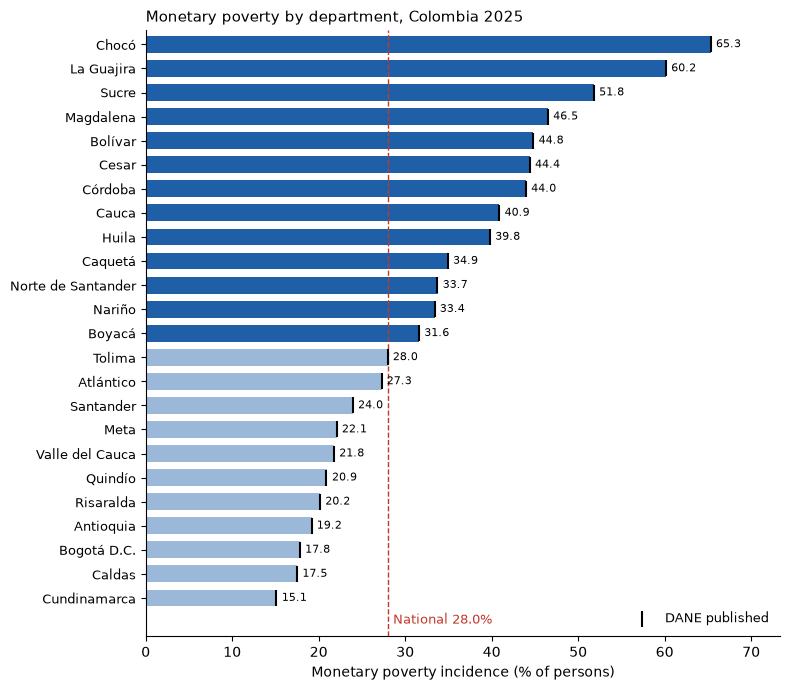

In [4]:
fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(dept))[::-1]
nat = official.POVERTY[(YEAR, "nacional")]
colors = np.where(dept["poverty"] > nat, "#1f5fa8", "#9bb8d9")
ax.barh(y, dept["poverty"], color=colors, height=0.7)
ax.scatter(dept["DANE_2025"], y, marker="|", s=120, color="black", zorder=3, label="DANE published")
ax.axvline(nat, color="#c0392b", ls="--", lw=1)
ax.text(nat + 0.6, -0.9, f"National {nat:.1f}%", color="#c0392b", fontsize=9, va="center")
ax.set_yticks(y)
ax.set_yticklabels(dept.index, fontsize=9)
for yi, v in zip(y, dept["poverty"]):
    ax.text(v + 0.6, yi, f"{v:.1f}", va="center", fontsize=8)
ax.set_xlabel("Monetary poverty incidence (% of persons)")
ax.set_title("Monetary poverty by department, Colombia 2025", loc="left", fontsize=11)
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_xlim(0, dept["poverty"].max() + 8)
ax.set_ylim(-1.6, len(dept) - 0.4)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIGS / "poverty_by_department_2025.png", dpi=200)
plt.show()

## 2. Poverty by sex of the household head

`hogares` has no sex variable, so the head's sex comes from `personas`:
keep the person with `p6050 == 1` (head) in each household, take `p3271` (1 = man, 2 = woman),
and merge on the household key (`directorio`, `secuencia_p`).
The merge is validated as one-to-one and every household must find exactly one head.

In [5]:
per = load(YEAR, "personas",
           columns=["directorio", "secuencia_p", "orden", "p6050", "p3271", "fex_c"])
print("personas loaded:", per.shape)

heads = household_head_sex(per)
m = hog.merge(heads, on=HH_KEYS, how="left", validate="one_to_one", indicator=True)
print(m["_merge"].value_counts().to_dict())
assert (m["_merge"] == "both").all(), "some households have no head"

personas loaded: (773932, 6)
{'both': 276666, 'left_only': 0, 'right_only': 0}


In [6]:
SEX = {1: "man", 2: "woman"}
rows = []
for code_, label in SEX.items():
    d = m[m["sexo_jefe"] == code_]
    rows.append({
        "group": f"Head is a {label}",
        "poverty": weighted_rate(d["pobre"], d["w_person"]),
        "DANE_poverty": official.SEX_2025[("poverty", "head", label)],
        "extreme": weighted_rate(d["indigente"], d["w_person"]),
        "DANE_extreme": official.SEX_2025[("extreme", "head", label)],
        "share_of_population": 100 * d["w_person"].sum() / m["w_person"].sum(),
        "mean_household_size": np.average(d["nper"], weights=d["fex"]),
    })

# Same rates by the person's own sex: attach the household's poverty status to every person
pp = per.merge(hog[HH_KEYS + ["pobre", "indigente"]], on=HH_KEYS, how="inner")
for code_, label in SEX.items():
    d = pp[pp["sexo"] == code_]
    rows.append({
        "group": f"Persons: {label}",
        "poverty": weighted_rate(d["pobre"], d["fex"]),
        "DANE_poverty": official.SEX_2025[("poverty", "population", label)],
        "extreme": weighted_rate(d["indigente"], d["fex"]),
        "DANE_extreme": official.SEX_2025[("extreme", "population", label)],
    })

sex = pd.DataFrame(rows).set_index("group")
sex.to_csv(RESULTS / "sex_2025.csv")
sex.round(2)

,poverty,DANE_poverty,extreme,DANE_extreme,share_of_population,mean_household_size
group,,,,,,
Head is a man,24.48,24.5,7.97,8.0,55.08,2.85
Head is a woman,32.33,32.3,11.69,11.7,44.92,2.81
Persons: man,26.83,26.8,9.17,9.2,NaN,NaN
Persons: woman,29.11,29.1,10.08,10.1,NaN,NaN


In [7]:
gap_head = sex.loc["Head is a woman", "poverty"] - sex.loc["Head is a man", "poverty"]
gap_pop = sex.loc["Persons: woman", "poverty"] - sex.loc["Persons: man", "poverty"]
print(f"Gap by sex of head:   {gap_head:.1f} pp   (DANE 7.8)")
print(f"Gap by own sex:       {gap_pop:.1f} pp   (DANE 2.3)")

Gap by sex of head:   7.9 pp   (DANE 7.8)
Gap by own sex:       2.3 pp   (DANE 2.3)


**Reading:** people living in female-headed households are much more likely to be poor
(about 8 pp) than the gap between women and men as individuals (about 2 pp) suggests.
The two groups have almost the same average household size (see `mean_household_size`), so
the gap is not about household size. It is a descriptive difference, not a causal effect:
female-headed households differ in number of earners, location and labour-market attachment.
Decomposing the gap would need a regression with those controls.

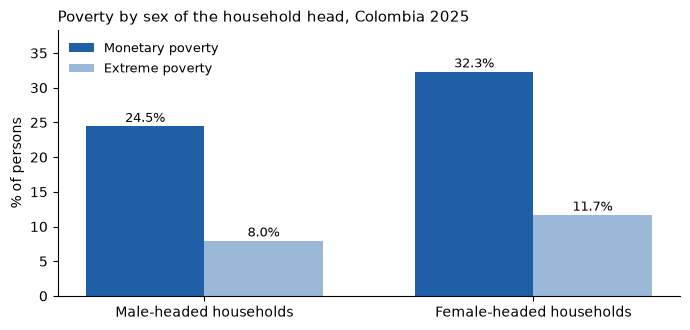

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
groups = ["Head is a man", "Head is a woman"]
x = np.arange(2)
ax.bar(x - 0.18, sex.loc[groups, "poverty"], width=0.36, color="#1f5fa8", label="Monetary poverty")
ax.bar(x + 0.18, sex.loc[groups, "extreme"], width=0.36, color="#9bb8d9", label="Extreme poverty")
for xi, g in zip(x, groups):
    ax.text(xi - 0.18, sex.loc[g, "poverty"] + 0.6, f"{sex.loc[g, 'poverty']:.1f}%", ha="center", fontsize=9)
    ax.text(xi + 0.18, sex.loc[g, "extreme"] + 0.6, f"{sex.loc[g, 'extreme']:.1f}%", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(["Male-headed households", "Female-headed households"])
ax.set_ylabel("% of persons")
ax.set_ylim(0, sex["poverty"].max() + 6)
ax.set_title("Poverty by sex of the household head, Colombia 2025", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIGS / "poverty_by_head_sex_2025.png", dpi=200)
plt.show()

## 3. Inequality and poverty across departments

Does higher poverty go with higher inequality? Each point is a department; the Gini is
computed with the hand-written weighted `gini()` on per-capita spending-unit income.

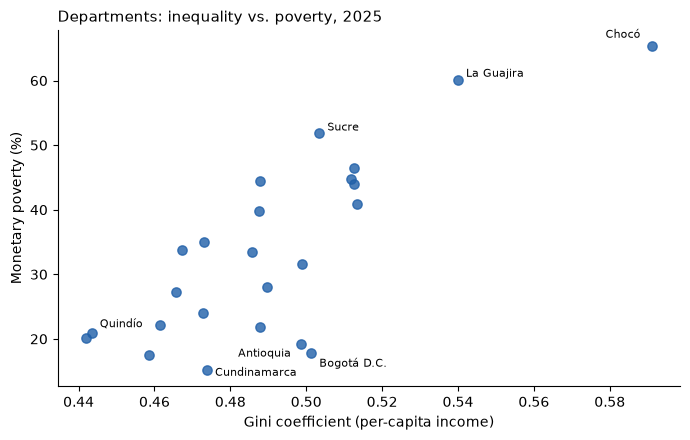

Correlation across the 24 departments (unweighted): 0.78
Without Chocó: 0.71


In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(dept["gini"], dept["poverty"], s=45, color="#1f5fa8", alpha=0.8)
offsets = {"Chocó": (-8, 6), "La Guajira": (6, 2), "Sucre": (6, 2), "Quindío": (6, 4),
           "Antioquia": (-7, -9), "Bogotá D.C.": (6, -10), "Cundinamarca": (6, -4)}
for name, (dx, dy) in offsets.items():
    r = dept.loc[name]
    ax.annotate(name, (r["gini"], r["poverty"]), xytext=(dx, dy), textcoords="offset points",
                fontsize=8, ha="right" if dx < 0 else "left")
ax.set_xlabel("Gini coefficient (per-capita income)")
ax.set_ylabel("Monetary poverty (%)")
ax.set_title("Departments: inequality vs. poverty, 2025", loc="left", fontsize=11)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIGS / "gini_vs_poverty_departments_2025.png", dpi=200)
plt.show()
print(f"Correlation across the 24 departments (unweighted): {dept[['gini', 'poverty']].corr().iloc[0, 1]:.2f}")
print(f"Without Chocó: {dept.drop('Chocó')[['gini', 'poverty']].corr().iloc[0, 1]:.2f}")

## 4. Sampling uncertainty (approximate 95% confidence intervals)

The public microdata contain the expansion factors but **no stratum or cluster (PSU)
identifiers**, so full design-based standard errors (e.g. with `samplics`) cannot be computed.
`ratio_se()` uses Taylor linearization of the ratio estimator
(poor persons / persons), with households as sampling units and the 25 survey domains
(`dominio`) as strata. Ignoring clustering usually makes standard errors **too small**, so these
intervals are a lower bound on the true uncertainty.

In [10]:
Z = 1.96
hog["poor_persons"] = hog["pobre"] * hog["nper"]
hog["extreme_persons"] = hog["indigente"] * hog["nper"]

def ci(d, y_col, weight="fex"):
    R, se = ratio_se(d[y_col], d["nper"], d[weight], d["dominio"])
    return {"estimate": 100 * R, "se": 100 * se,
            "ci_low": 100 * (R - Z * se), "ci_high": 100 * (R + Z * se)}

rows = []
for dom, d in {"nacional": hog, "cabeceras": hog[hog["clase"] == 1], "rural": hog[hog["clase"] == 2]}.items():
    for ind, col in [("poverty", "poor_persons"), ("extreme", "extreme_persons")]:
        rows.append({"group": dom, "indicator": ind, **ci(d, col)})
for dpto, d in hog.groupby("dpto"):
    rows.append({"group": dpto, "indicator": "poverty", **ci(d, "poor_persons", weight="fex_dpto")})
cis = pd.DataFrame(rows)
cis.to_csv(RESULTS / "confidence_intervals_2025.csv", index=False)
cis.head(6).round(2)

,group,indicator,estimate,se,ci_low,ci_high
0,nacional,poverty,28.00,0.17,27.67,28.34
1,nacional,extreme,9.64,0.11,9.41,9.86
2,cabeceras,poverty,24.61,0.18,24.25,24.96
3,cabeceras,extreme,6.85,0.10,6.65,7.06
4,rural,poverty,39.48,0.41,38.68,40.29
5,rural,extreme,19.06,0.34,18.38,19.73


In [11]:
dept_ci = cis[(cis["indicator"] == "poverty") & ~cis["group"].isin(["nacional", "cabeceras", "rural"])]
print(f"Department CI half-widths: {(Z * dept_ci['se']).min():.1f} to {(Z * dept_ci['se']).max():.1f} pp "
      f"(national: {Z * cis.loc[0, 'se']:.2f} pp)")

Department CI half-widths: 1.0 to 2.6 pp (national: 0.33 pp)


## 5. Notes for the write-up

- Departmental rates replicate DANE's published figures when `fex_dpto` is used; with the
  national factor `fex_c` some departments are off by several points (largest: La Guajira).
- Poverty ranges from about 15% (Cundinamarca) to 65% (Chocó).
- Persons in female-headed households: ~32% poor vs ~25% in male-headed households (DANE: 32.3 vs 24.5).
- Departmental Ginis are sample estimates from a few thousand households each; small
  departments carry more sampling error than the national figure.
- Approximate 95% CI for national poverty: about ±0.3 pp; departments about ±1–2 pp
  (lower bounds, since clustering is ignored).